<a href="https://colab.research.google.com/github/projetml9/IPL-Team-Player-Performance-Analysis/blob/main/IPL_Team_%26_Player_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IPL Team & Player Performance Analysis

## 1. Project Overview
This project presents a data-driven analysis of the Indian Premier League (IPL), covering the performance of teams and individual players from the 2008 season to the 2026 season. Using ball-by-ball data, the study examines match outcomes, batting and bowling records, and the influence of factors such as the toss, venue and phase of play. A machine learning component is also included to assess how well match results can be predicted from pre-match information.

## 2. Objectives
- To evaluate team performance through win percentage, season-wise results and head-to-head records.
- To analyse the impact of the toss decision and venue on match outcomes.
- To identify leading batters and bowlers using key metrics such as runs, strike rate, average, wickets and economy rate.
- To study how scoring rate and wickets vary across the Powerplay, Middle and Death overs.
- To build and evaluate predictive models for match outcomes.

## 3. Dataset
- **Source:** IPL ball-by-ball dataset (`IPL.csv`).
- **Scope:** 1,243 matches and approximately 295,000 deliveries, from 2008 to 2026.
- **Contents:** Each record describes a single delivery, including the batter, bowler, runs scored, extras, dismissals, teams, toss details, venue and match result.

## 4. Methodology
1. **Data cleaning:** Standardised franchise names that changed over time and merged duplicate venue names. Created a season variable from the match date. Excluded super overs from player statistics, and excluded tied and no-result matches from win analysis.
2. **Exploratory analysis:** Aggregated the data at team, player, venue and phase levels, and visualised the results using bar charts, stacked charts and heatmaps.
3. **Modelling:** Trained Logistic Regression and Random Forest classifiers to predict match winners, and compared their accuracy against a baseline.

## 5. Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Google Colab.

## 6. Limitations
The dataset contains no information on player form, pitch conditions, weather or team composition for individual matches. As a result, the prediction models are limited in accuracy, and their results should be treated as indicative rather than conclusive.

***Import libraries
pandas holds the data in tables (DataFrames) and does the grouping and counting.
numpy handles the maths, such as dividing safely when a number is zero.
matplotlib and seaborn draw the charts. Seaborn sits on top of matplotlib and looks cleaner.
warnings.filterwarnings("ignore") hides harmless warning messages.
sns.set_style("whitegrid") and plt.rcParams[...] set a default grid style and chart size.***


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

***Load the data
files.upload() opens a file picker in Colab. The file is saved in Colab’s temporary storage.
pd.read_csv(...) reads it into the table df. low_memory=False stops pandas guessing column types in chunks, which can cause type errors on big files.
df.shape gives (rows, columns). Here that is about 295,000 rows, one per ball bowled.
df["match_id"].nunique() counts the distinct matches, 1,243.***

Saving IPL.csv to IPL.csv
Shape: (295732, 64)
Matches: 1243


,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter
0,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,0.1,...,1,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN
1,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,0.2,...,2,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN
2,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,0.3,...,2,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN


***Clean the data***

***Raw data is inconsistent, so every later result would be wrong without this step.***

***Team names: replace(team_map) turns “Delhi Daredevils” into “Delhi Capitals” and so on, so one franchise isn’t counted as two teams.
Venue names: The same ground appears as “Wankhede Stadium” and “Wankhede Stadium, Mumbai”. The venue map merges these.
Season: The file’s season column is messy (“2007/08”, “2009/10”), so the code uses the year from the match date instead.
Renaming and wicket flag: batter is renamed batsman. is_wicket is 1 whenever someone was dismissed on that ball.
d is the ball-by-ball table with super overs removed (innings 3 and above). Super overs would distort normal batting and bowling stats. over_no turns the file’s 0-19 over numbering into 1-20.
matches keeps one row per match with drop_duplicates("match_id"). It drops ties and no-results because there is no winner to analyse.
team1 and team2: team1 is the side that batted first and team2 the side that chased. They are worked out from who batted in each innings.***

In [ ]:
# 1. Team names
team_map = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}
for c in ["batting_team", "bowling_team", "toss_winner", "match_won_by"]:
    df[c] = df[c].replace(team_map)

# 2. Venue names (same ground, different spellings)
venue_map = {
    "Arun Jaitley Stadium, Delhi": "Arun Jaitley Stadium",
    "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "Brabourne Stadium, Mumbai": "Brabourne Stadium",
    "Dr DY Patil Sports Academy, Mumbai": "Dr DY Patil Sports Academy",
    "Eden Gardens, Kolkata": "Eden Gardens",
    "M Chinnaswamy Stadium, Bengaluru": "M Chinnaswamy Stadium",
    "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",
    "MA Chidambaram Stadium, Chepauk": "MA Chidambaram Stadium",
    "MA Chidambaram Stadium, Chepauk, Chennai": "MA Chidambaram Stadium",
    "Maharashtra Cricket Association Stadium, Pune": "Maharashtra Cricket Association Stadium",
    "Punjab Cricket Association IS Bindra Stadium, Mohali": "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh": "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association Stadium, Mohali": "Punjab Cricket Association IS Bindra Stadium",
    "Rajiv Gandhi International Stadium, Uppal": "Rajiv Gandhi International Stadium",
    "Rajiv Gandhi International Stadium, Uppal, Hyderabad": "Rajiv Gandhi International Stadium",
    "Sawai Mansingh Stadium, Jaipur": "Sawai Mansingh Stadium",
    "Wankhede Stadium, Mumbai": "Wankhede Stadium",
    "Zayed Cricket Stadium, Abu Dhabi": "Sheikh Zayed Stadium",
    "Sardar Patel Stadium, Motera": "Narendra Modi Stadium, Ahmedabad",
}
df["venue"] = df["venue"].replace(venue_map)

# 3. Season, column names, wicket flag
df["date"] = pd.to_datetime(df["date"])
df["season"] = df["date"].dt.year
df = df.rename(columns={"batter": "batsman"})
df["is_wicket"] = df["player_out"].notnull().astype(int)

# 4. Ball-by-ball without super overs (innings 3+), overs numbered 1-20
d = df[df["innings"] <= 2].copy()
d["over_no"] = d["over"] + 1

# 5. One row per match, only matches with a winner
matches = df.drop_duplicates("match_id").copy()
matches = matches[matches["result_type"].isnull()].copy()

# 6. team1 = batted first, team2 = batted second
order = d.groupby("match_id")["batting_team"].unique()
matches = matches.set_index("match_id")
matches["team1"] = order.str[0]
matches["team2"] = order.str[1]
matches = matches.reset_index()

print("Matches with a result:", len(matches))
print("Deliveries analysed:", len(d))

Matches with a result: 1218
Deliveries analysed: 295557


***Team analysis***

***played counts how many matches each team appeared in (as team1 or team2).
won counts wins from match_won_by.
Win % is Won divided by Played, times 100.
The chart only includes teams with at least 50 matches, so short-lived franchises don’t distort it.***

***Graph: horizontal bar chart of Win %. Each bar is one team and a longer bar means a higher win rate.***

***Gujarat Titans lead at 61%, but they’ve played only 77 matches, so that number is less reliable.
Among established teams, Chennai Super Kings (56%) and Mumbai Indians (54%) are best, followed by KKR (52%) and RCB (51%).
Punjab Kings (46%) and Delhi Capitals (46%) have won less than half their matches.***

,Played,Won,Win %
Gujarat Titans,77,47,61.04
Chennai Super Kings,264,148,56.06
Mumbai Indians,287,155,54.01
Kolkata Knight Riders,271,140,51.66
Royal Challengers Bengaluru,280,143,51.07
Rajasthan Royals,245,123,50.20
Rising Pune Supergiant,30,15,50.00
Sunrisers Hyderabad,206,102,49.51
Lucknow Super Giants,70,34,48.57
Punjab Kings,271,126,46.49


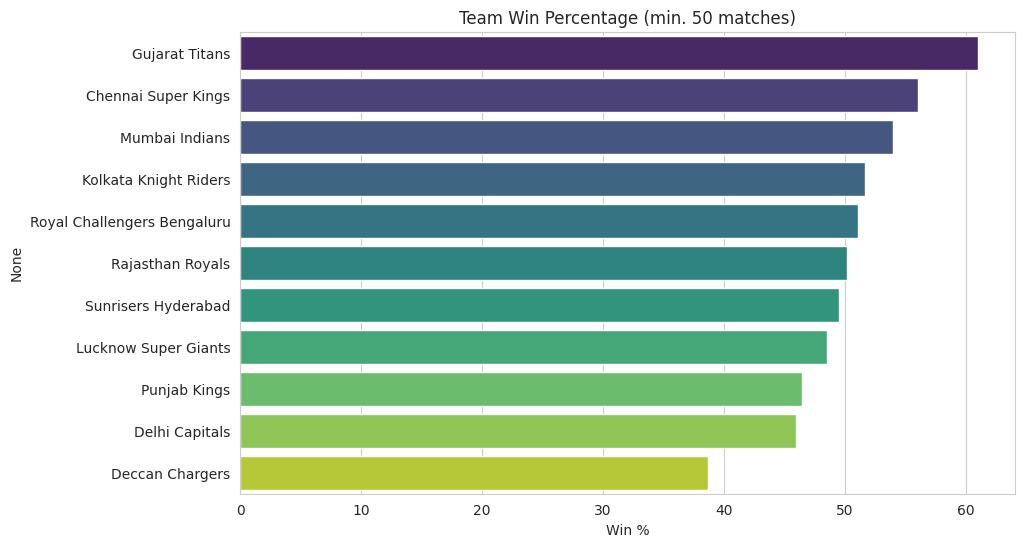

In [ ]:
played = pd.concat([matches["team1"], matches["team2"]]).value_counts()
won = matches["match_won_by"].value_counts()

team_stats = pd.DataFrame({"Played": played, "Won": won}).fillna(0)
team_stats["Win %"] = (team_stats["Won"] / team_stats["Played"] * 100).round(2)
team_stats = team_stats.sort_values("Win %", ascending=False)
display(team_stats)

main = team_stats[team_stats["Played"] >= 50]
plt.figure(figsize=(10, 6))
sns.barplot(x=main["Win %"], y=main.index, palette="viridis")
plt.title("Team Win Percentage (min. 50 matches)")
plt.show()

***Season-wise performance***

***Code: Counts matches per year, then groups by season and team to find the team with the most wins in each season. idxmax() picks the top row per season.***

***Graph 1: Matches per season (bar chart). It shows how the tournament has grown.***

***About 56-60 matches per season in the 8-team years.
72-76 matches in 2011-2013 (9 teams and a longer format).
74 matches from 2022 onwards, when the league grew to 10 teams.***

***The table lists each season’s most successful team and its win count, such as Gujarat Titans in 2023 and Kolkata Knight Riders in 2024 (11 wins each in those examples). It shows how leadership rotates between franchises.***

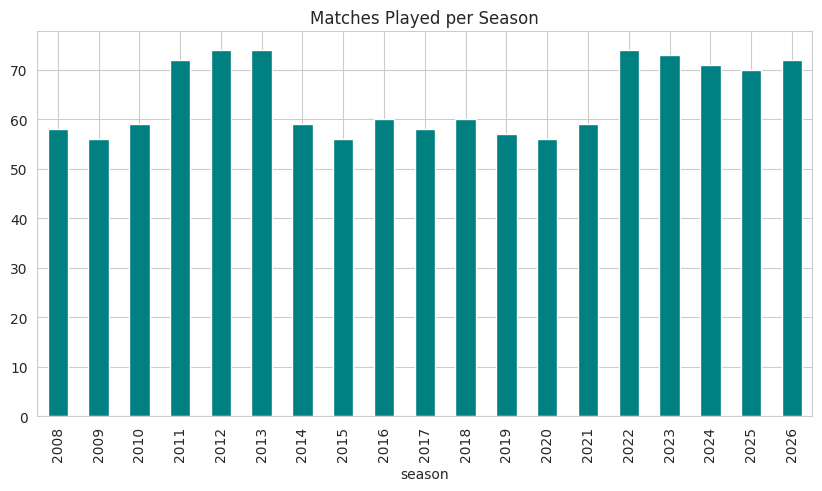

,season,match_won_by,wins
6,2008,Rajasthan Royals,13
10,2009,Delhi Capitals,10
20,2010,Mumbai Indians,11
24,2011,Chennai Super Kings,11
37,2012,Kolkata Knight Riders,12
46,2013,Mumbai Indians,13
56,2014,Punjab Kings,12
60,2015,Chennai Super Kings,10
75,2016,Sunrisers Hyderabad,11
79,2017,Mumbai Indians,11


In [ ]:
matches["season"].value_counts().sort_index().plot(kind="bar", color="teal")
plt.title("Matches Played per Season")
plt.show()

sw = matches.groupby(["season", "match_won_by"]).size().reset_index(name="wins")
display(sw.loc[sw.groupby("season")["wins"].idxmax()])

***Toss analysis***

***Code: Compares toss_winner with match_won_by, then groups toss decisions by season.***

***Printed result: Toss winners won 51.6% of matches, barely better than a coin flip. So the toss has a small effect.***

***Graph 1: Stacked bar of toss decisions by season. Each bar splits into “bat” and “field”.***

***In 2008 the split was nearly even (26 bat, 32 field).
By 2017 captains chose to field 48 times out of 58.
By 2026 it was 60 field against 12 bat.
This is a clear trend: captains now overwhelmingly prefer to chase. The reasons are that the target is known, dew helps batting second in evening games, and teams have got good at chasing.***

***Graph 2: Win rate of toss winners by decision. Teams that chose to field won about 54.7%, against 45.3% for those that chose to bat. This supports the shift in graph 1: fielding first has paid off more often.***

Toss winner won the match: 51.56%


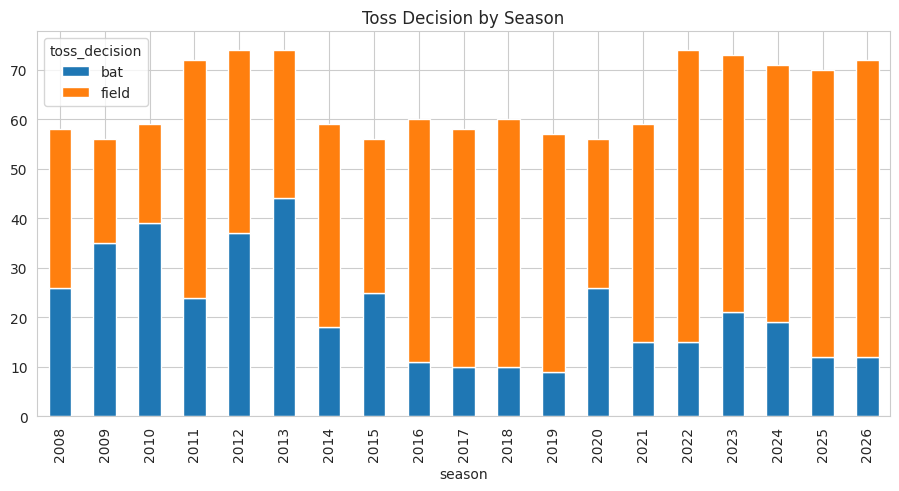

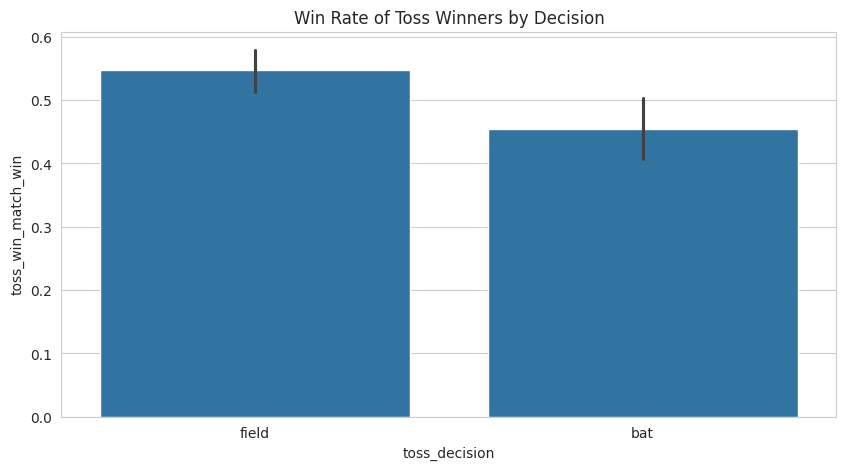

In [ ]:
toss_win = (matches["toss_winner"] == matches["match_won_by"]).mean() * 100
print(f"Toss winner won the match: {toss_win:.2f}%")

dec = matches.groupby(["season", "toss_decision"]).size().unstack().fillna(0)
dec.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Toss Decision by Season")
plt.show()

matches["toss_win_match_win"] = matches["toss_winner"] == matches["match_won_by"]
sns.barplot(data=matches, x="toss_decision", y="toss_win_match_win")
plt.title("Win Rate of Toss Winners by Decision")
plt.show()

***Venue and head-to-head analysis***

***Venue code: value_counts().head(10) counts matches per ground. Because the names were cleaned, each ground appears once.***

***Graph 1: Top 10 venues (horizontal bar).***

***Wankhede Stadium hosts the most (131).
Next are Eden Gardens (105), Arun Jaitley Stadium (101), M Chinnaswamy Stadium (100) and MA Chidambaram Stadium (96).***

***Head-to-head code: It goes through every match and finds the winner and loser. It then adds 1 to h2h[winner][loser], so a cell reads “row team beat column team this many times”.***

***Graph 2: Head-to-head heatmap. Darker cells mean more wins. Read along a row to see who that team beats most. Examples:***

***CSK vs MI is almost even (CSK 20, MI 21).
Mumbai Indians beat KKR 25 times to KKR’s 12.
KKR beat Punjab Kings 21 times to 13.***

***Diagonal cells are always 0, since a team can’t play itself.***

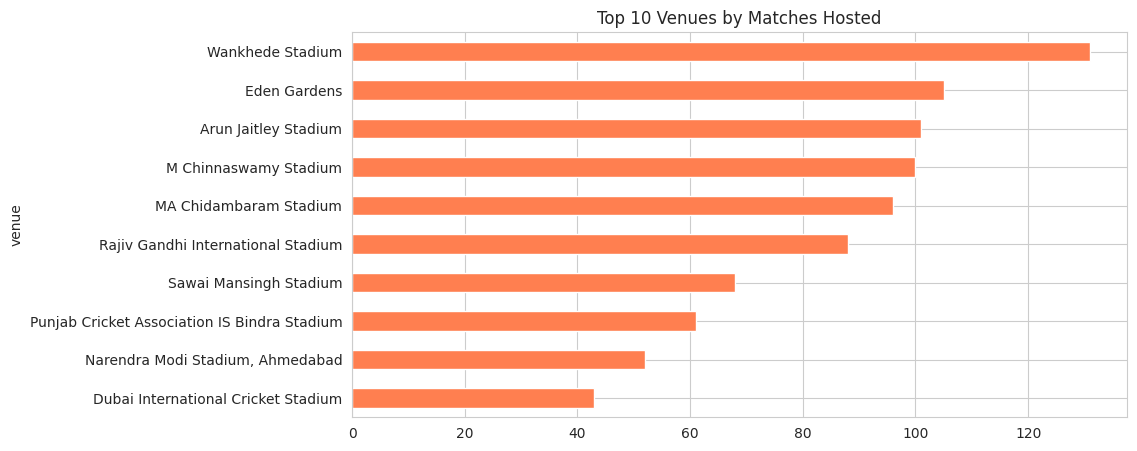

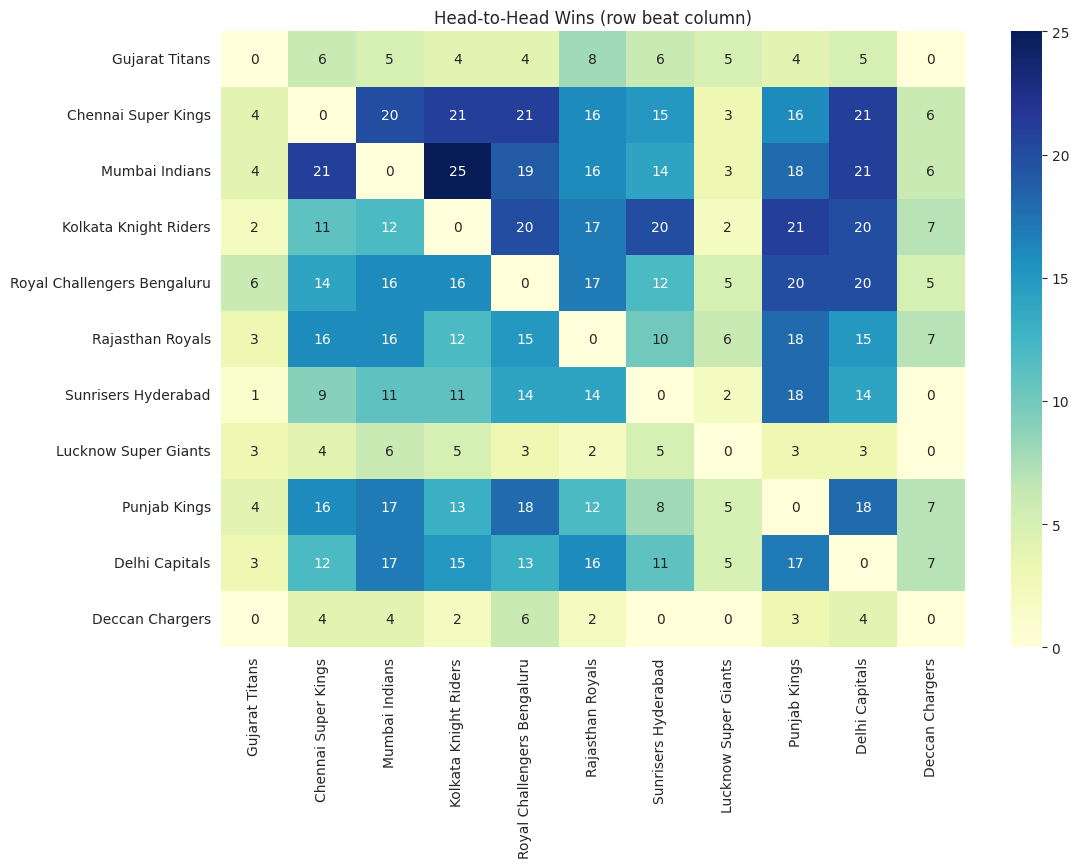

In [ ]:
matches["venue"].value_counts().head(10).plot(kind="barh", color="coral")
plt.title("Top 10 Venues by Matches Hosted")
plt.gca().invert_yaxis()
plt.show()

teams = team_stats[team_stats["Played"] >= 50].index.tolist()
h2h = pd.DataFrame(0, index=teams, columns=teams)
for _, r in matches.iterrows():
    w = r["match_won_by"]
    l = r["team2"] if r["team1"] == w else r["team1"]
    if w in teams and l in teams:
        h2h.loc[w, l] += 1

plt.figure(figsize=(12, 8))
sns.heatmap(h2h, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Head-to-Head Wins (row beat column)")
plt.show()

***Batting analysis***


***groupby("batsman").agg(...) builds one row per batter: total runs, balls faced, fours, sixes and innings.
dismissals counts how many times each player got out (retired hurt excluded).
Strike rate = runs ÷ balls × 100 (runs per 100 balls).
Average = runs ÷ dismissals (runs per time out).
The balls >= 500 filter removes players with tiny samples, who could otherwise top the strike rate list.***

***Graph 1: Top 10 run scorers. V Kohli leads (about 9,336 runs), then RG Sharma (7,329) and S Dhawan (6,769).***

***Graph 2: Top 10 strike rates (min. 500 balls). Leaders include TH David (about 177), PD Salt (174) and AD Russell (174). These are power hitters who score fast but not always for long.***

***Graph 3: Most sixes. CH Gayle (357) is clear at the top, ahead of RG Sharma (324) and V Kohli (317).***

***How to read these together: Total runs rewards longevity, strike rate rewards speed, and average rewards consistency. Kohli has a high average (about 40), while Russell has a much lower one (about 28) with a much higher strike rate. That is a good talking point in your report.***

,runs,balls,fours,sixes,innings,dismissals,strike_rate,average
batsman,,,,,,,,
V Kohli,9336,6926,845,317,275,231.0,134.80,40.42
RG Sharma,7329,5514,661,324,275,245.0,132.92,29.91
S Dhawan,6769,5324,768,153,221,192.0,127.14,35.26
DA Warner,6565,4697,663,236,184,162.0,139.77,40.52
KL Rahul,5815,4179,508,239,149,126.0,139.15,46.15
SK Raina,5528,4043,506,203,200,170.0,136.73,32.52
MS Dhoni,5439,3957,375,264,241,142.0,137.45,38.30
AM Rahane,5367,4273,540,141,197,178.0,125.60,30.15
SV Samson,5181,3671,432,243,185,163.0,141.13,31.79


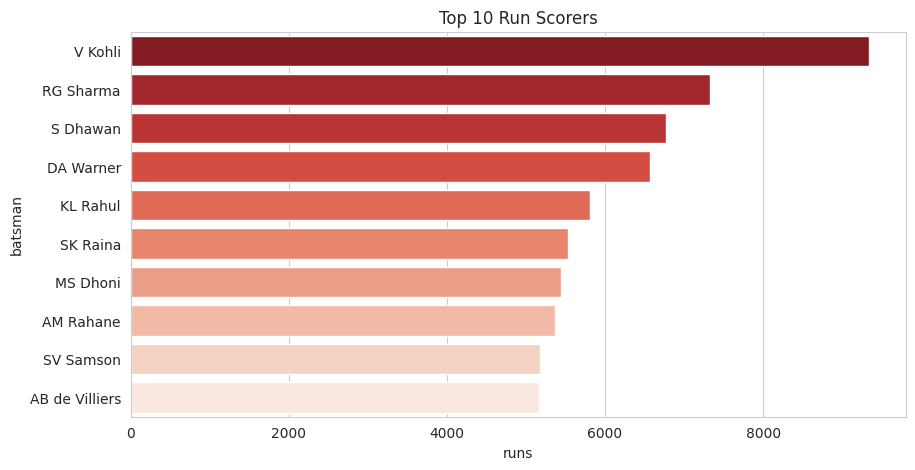

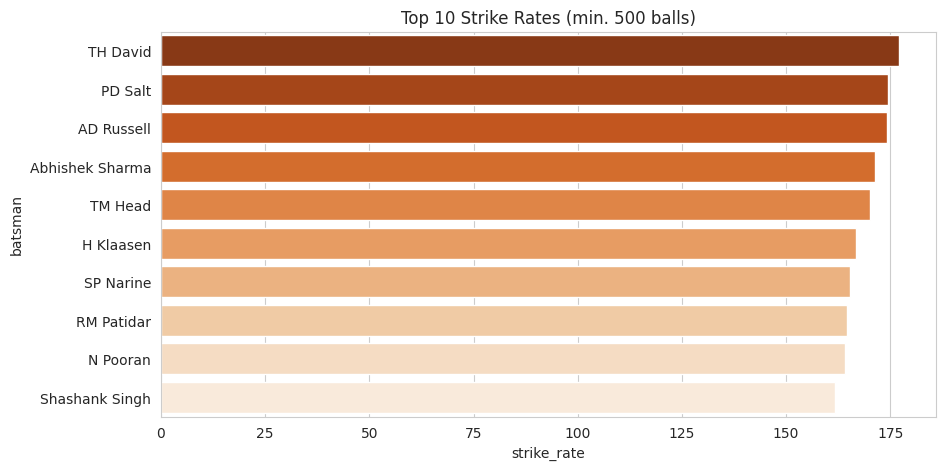

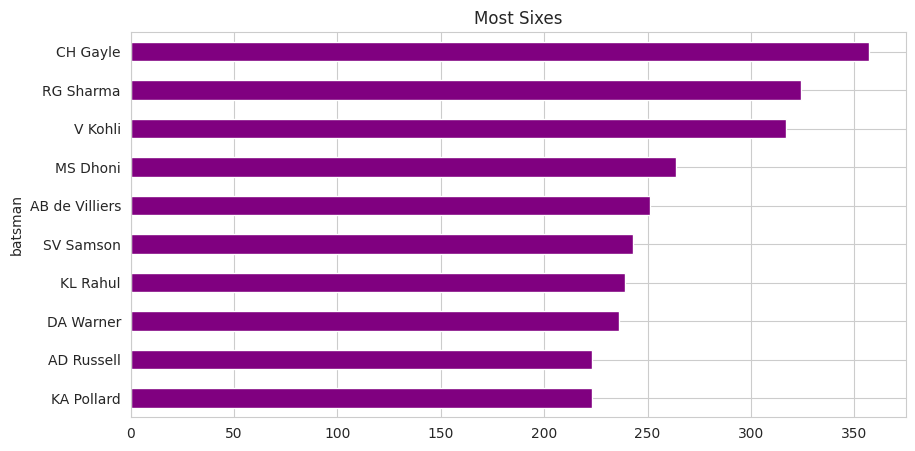

In [ ]:
bat = d.groupby("batsman").agg(
    runs=("runs_batter", "sum"),
    balls=("balls_faced", "sum"),
    fours=("runs_batter", lambda x: (x == 4).sum()),
    sixes=("runs_batter", lambda x: (x == 6).sum()),
    innings=("match_id", "nunique"),
)
out = d[d["player_out"].notnull() & (d["wicket_kind"] != "retired hurt")]
bat["dismissals"] = out["player_out"].value_counts()
bat["dismissals"] = bat["dismissals"].fillna(0)
bat["strike_rate"] = (bat["runs"] / bat["balls"] * 100).round(2)
bat["average"] = (bat["runs"] / bat["dismissals"].replace(0, np.nan)).round(2)

top_runs = bat.sort_values("runs", ascending=False).head(10)
display(top_runs)
sns.barplot(x=top_runs["runs"], y=top_runs.index, palette="Reds_r")
plt.title("Top 10 Run Scorers")
plt.show()

top_sr = bat[bat["balls"] >= 500].sort_values("strike_rate", ascending=False).head(10)
sns.barplot(x=top_sr["strike_rate"], y=top_sr.index, palette="Oranges_r")
plt.title("Top 10 Strike Rates (min. 500 balls)")
plt.show()

bat["sixes"].sort_values(ascending=False).head(10).plot(kind="barh", color="purple")
plt.title("Most Sixes")
plt.gca().invert_yaxis()
plt.show()

***Bowling analysis***

***Wickets exclude run-outs, retired hurt/out and obstructing the field, because those aren’t credited to the bowler.
runs_bowler already leaves out byes and leg-byes, which aren’t charged to the bowler.
valid_ball counts only legal deliveries, so wides and no-balls don’t count as balls bowled.
Economy = runs conceded ÷ overs bowled (overs = legal balls ÷ 6).
Average = runs conceded ÷ wickets.***

***Graph 1: Top 10 wicket takers. YS Chahal leads (233), then B Kumar (226), SP Narine (207), PP Chawla (192), and R Ashwin and JJ Bumrah (187 each).***

***Graph 2: Best economy (min. 500 balls). Leaders include A Kumble (6.58), M Muralitharan (6.68) and SP Narine (6.79). Narine stands out because he combines a very low economy with 207 wickets over a long career.***

***Wickets measure volume and economy measures control. Chahal takes the most wickets but is more expensive (8.05), while Narine is both economical and prolific.***

,runs_conceded,legal_balls,wickets,economy,average
bowler,,,,,
YS Chahal,5417,4037,233.0,8.05,23.25
B Kumar,5913,4600,226.0,7.71,26.16
SP Narine,5261,4651,207.0,6.79,25.42
PP Chawla,5108,3850,192.0,7.96,26.60
R Ashwin,5652,4710,187.0,7.20,30.22
JJ Bumrah,4441,3631,187.0,7.34,23.75
DJ Bravo,4360,3120,183.0,8.38,23.83
RA Jadeja,5465,4254,180.0,7.71,30.36
Rashid Khan,4282,3530,179.0,7.28,23.92


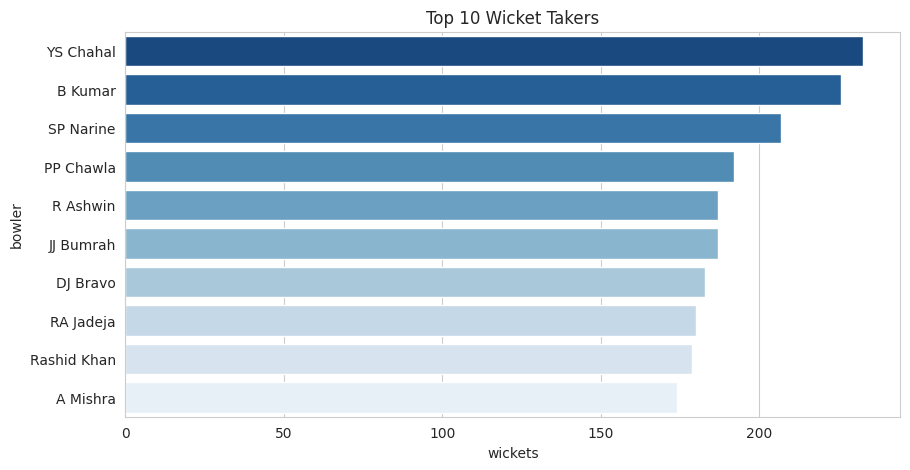

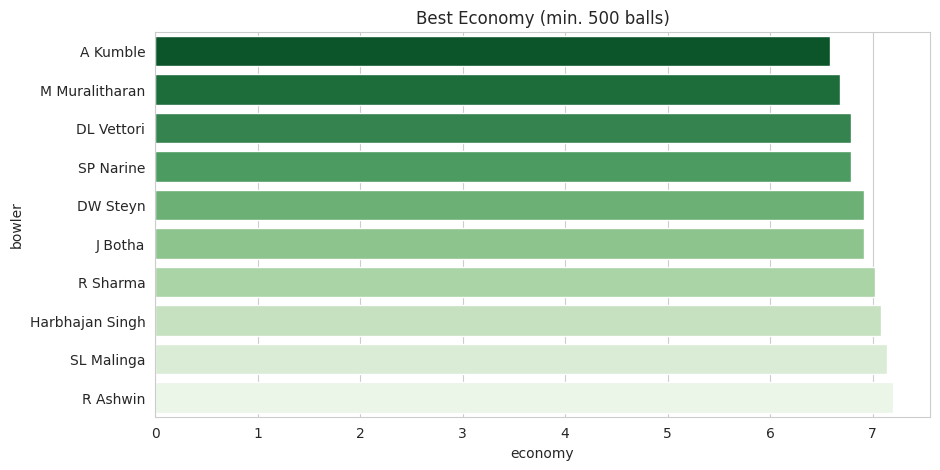

In [ ]:
not_bowler = ["run out", "retired hurt", "retired out", "obstructing the field"]
wk = d[(d["is_wicket"] == 1) & (~d["wicket_kind"].isin(not_bowler))]

bowl = d.groupby("bowler").agg(
    runs_conceded=("runs_bowler", "sum"),
    legal_balls=("valid_ball", "sum"),
)
bowl["wickets"] = wk.groupby("bowler").size()
bowl["wickets"] = bowl["wickets"].fillna(0)
bowl["economy"] = (bowl["runs_conceded"] / (bowl["legal_balls"] / 6)).round(2)
bowl["average"] = (bowl["runs_conceded"] / bowl["wickets"].replace(0, np.nan)).round(2)

top_w = bowl.sort_values("wickets", ascending=False).head(10)
display(top_w)
sns.barplot(x=top_w["wickets"], y=top_w.index, palette="Blues_r")
plt.title("Top 10 Wicket Takers")
plt.show()

eco = bowl[bowl["legal_balls"] >= 500].sort_values("economy").head(10)
sns.barplot(x=eco["economy"], y=eco.index, palette="Greens_r")
plt.title("Best Economy (min. 500 balls)")
plt.show()

***Phase analysis***

***pd.cut(d["over_no"], [0, 6, 15, 20], ...) puts each over into Powerplay (overs 1-6), Middle (7-15) or Death (16-20). Then runs, legal balls and wickets are summed per phase, and run rate = runs ÷ balls × 6.***

***Graph 1: Run rate by phase (bar chart).***

***Powerplay: about 8.09 runs per over.
Middle overs: about 7.95, the slowest phase, as batters consolidate against spinners and field restrictions are lifted.
Death overs: about 10.06, the fastest, as batters go all out.***

***Wickets (in the table): There is about one wicket per 25 balls in the powerplay and per 23 in the middle overs, but one per 12 balls in the death overs. Teams score fastest at the end, but they also lose wickets fastest. That risk-versus-reward trade-off is the core of T20 strategy.***

***Death-over batters table (min. 300 balls): AB de Villiers tops it with a strike rate of about 223, followed by RR Pant (203), AD Russell (196), TH David (195) and JC Buttler (193).***

,runs,balls,wickets,run_rate
phase,,,,
Powerplay (1-6),120188,89153,3583,8.09
Middle (7-15),174283,131526,5708,7.95
Death (16-20),106952,63786,5383,10.06


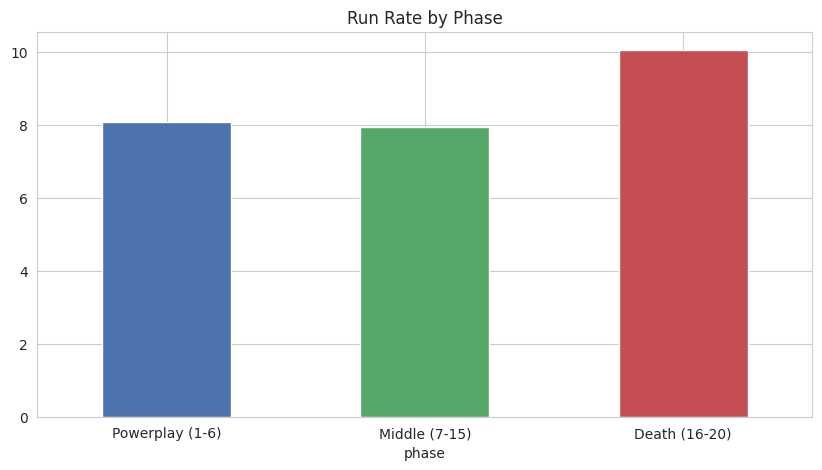

,runs,balls,strike_rate
batsman,,,
AB de Villiers,1868,838,222.91
RR Pant,1095,540,202.78
AD Russell,1432,731,195.90
TH David,843,432,195.14
JC Buttler,804,417,192.81
H Klaasen,738,383,192.69
SV Samson,852,446,191.03
RK Singh,791,417,189.69
V Kohli,1573,835,188.38


In [ ]:
d["phase"] = pd.cut(d["over_no"], [0, 6, 15, 20],
                    labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"])

phase = d.groupby("phase").agg(
    runs=("runs_total", "sum"),
    balls=("valid_ball", "sum"),
    wickets=("is_wicket", "sum"),
)
phase["run_rate"] = (phase["runs"] / phase["balls"] * 6).round(2)
display(phase)

phase["run_rate"].plot(kind="bar", color=["#4c72b0", "#55a868", "#c44e52"])
plt.title("Run Rate by Phase")
plt.xticks(rotation=0)
plt.show()

death = d[d["phase"] == "Death (16-20)"]
dd = death.groupby("batsman").agg(runs=("runs_batter", "sum"), balls=("balls_faced", "sum"))
dd["strike_rate"] = (dd["runs"] / dd["balls"] * 100).round(2)
display(dd[dd["balls"] >= 300].sort_values("strike_rate", ascending=False).head(10))

***Player of the Match***

***Counts how many times each name appears in player_of_match.***

***Graph: Horizontal bar of the top 10. AB de Villiers leads (24), then CH Gayle (22), RG Sharma and V Kohli (21 each), and MS Dhoni and DA Warner (18 each). Almost all are batters, which suggests batting performances tend to be rewarded more often than bowling ones in this award.***

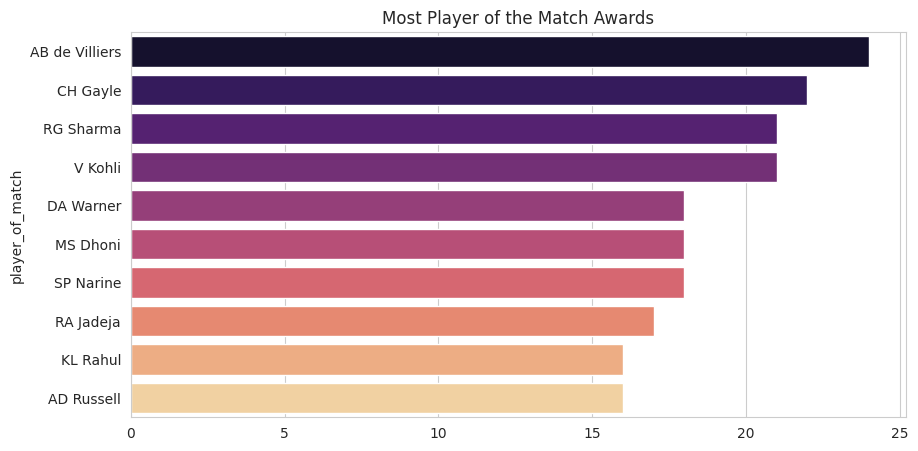

In [ ]:
pom = matches["player_of_match"].value_counts().head(10)
sns.barplot(x=pom.values, y=pom.index, palette="magma")
plt.title("Most Player of the Match Awards")
plt.show()

***Match winner prediction***

***Target (y): 1 if the team that batted first (team1) won, otherwise 0.
Features (X): team1, team2, toss decision, venue, and whether team1 won the toss.
train_test_split keeps 80% of matches for learning and 20% for testing. stratify=y keeps the win/loss ratio equal in both sets.
OneHotEncoder converts text columns (team names, venues) into 0/1 columns, since models need numbers.
Pipeline bundles encoding and model together, so test data is processed exactly like training data.
Logistic Regression is a simple, fast model. Random Forest builds many decision trees and averages them.
Baseline is the accuracy you’d get by always predicting “the chasing team wins” (about 55%).***

***Result: Both models scored 51-54%, which is no better than the baseline. The features simply don’t contain enough information to predict cricket outcomes. The honest takeaway for your report is that toss, venue and team names alone are weak predictors, and a better model would need player form and recent team performance.***

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ml = matches[["team1", "team2", "toss_winner", "toss_decision", "venue", "match_won_by"]].copy()
ml["y"] = (ml["match_won_by"] == ml["team1"]).astype(int)
ml["toss_won_by_team1"] = (ml["toss_winner"] == ml["team1"]).astype(int)

X = ml[["team1", "team2", "toss_decision", "venue", "toss_won_by_team1"]]
y = ml["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

pre = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"),
      ["team1", "team2", "toss_decision", "venue"])],
    remainder="passthrough")

print(f"Baseline (always predict chasing team wins): {1 - y.mean():.3f}")
for name, model in {"Logistic Regression": LogisticRegression(max_iter=1000),
                    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42)}.items():
    pipe = Pipeline([("prep", pre), ("model", model)]).fit(X_train, y_train)
    print(f"{name} accuracy: {accuracy_score(y_test, pipe.predict(X_test)):.3f}")

Baseline (always predict chasing team wins): 0.547
Logistic Regression accuracy: 0.533
Random Forest accuracy: 0.512


***Save results***

***to_csv(...) writes the team, batting and bowling tables to CSV files, and files.download(...) sends them to your computer. You can use them in Excel or Power BI, or attach them to your report.***

In [ ]:
team_stats.to_csv("team_stats.csv")
bat.sort_values("runs", ascending=False).to_csv("batting_stats.csv")
bowl.sort_values("wickets", ascending=False).to_csv("bowling_stats.csv")
for f in ["team_stats.csv", "batting_stats.csv", "bowling_stats.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>